In [3]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score
)

In [6]:
df = pd.read_csv("../part1/cleaned_dataset.csv")

df.head()

,Student_Name,College_Name,Stream,Year_of_Study,AI_Tools_Used,Daily_Usage_Hours,Use_Cases,Trust_in_AI_Tools,Impact_on_Grades,Do_Professors_Allow_Use,Preferred_AI_Tool,Awareness_Level,Willing_to_Pay_for_Access,State,Device_Used,Internet_Access
0,Aarav,Indian Institute of Information Technology,Engineering,4,Gemini,0.9,"Assignments, Coding Help",2,2,No,Copilot,9,Yes,Uttar pradesh,Mobile,Poor
1,Vivaan,"Government Ram Bhajan Rai NES College, Jashpur",Commerce,2,ChatGPT,3.4,Learning new topics,3,-3,Yes,Other,6,No,Chhattisgarh,Laptop,Poor
2,Aditya,Dolphin PG Institute of BioMedical & Natural,Science,2,Copilot,3.6,"MCQ Practice, Projects",5,0,No,Gemini,1,No,Uttarakhand,Tablet,Poor
3,Vihaan,Shaheed Rajguru College of Applied Sciences for,Arts,2,Copilot,2.9,Content Writing,5,2,Yes,Gemini,5,No,Delhi ncr,Laptop,High
4,Arjun,Roorkee College of Engineering,Science,1,Gemini,0.9,"Doubt Solving, Resume Writing",1,3,Yes,Other,8,Yes,Uttarakhand,Laptop,Medium


In [12]:
# Regression Target
y_reg = df["Impact_on_Grades"]

# Feature Matrix
X = df.drop(columns=["Impact_on_Grades"])

# Classification Target
y_clf = (y_reg > y_reg.median()).astype(int)

# Find categorical columns
categorical_cols = X.select_dtypes(include=["object"]).columns

# One-Hot Encoding
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

print(X.shape)

(3614, 1681)


In [13]:
X_train, X_test, y_clf_train, y_clf_test = train_test_split(
    X,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
# Task 1 - Default Decision Tree

dt_default = DecisionTreeClassifier(random_state=42)

dt_default.fit(X_train_scaled, y_clf_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [16]:
# Training Prediction
train_pred = dt_default.predict(X_train_scaled)

# Test Prediction
test_pred = dt_default.predict(X_test_scaled)

# Accuracy
train_acc = accuracy_score(y_clf_train, train_pred)
test_acc = accuracy_score(y_clf_test, test_pred)

print("=" * 50)
print("Default Decision Tree")
print("=" * 50)
print(f"Training Accuracy : {train_acc:.4f}")
print(f"Testing Accuracy  : {test_acc:.4f}")

Default Decision Tree
Training Accuracy : 1.0000
Testing Accuracy  : 0.7676


In [17]:
# Task 2 - Controlled Decision Tree

dt_control = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    random_state=42
)

dt_control.fit(X_train_scaled, y_clf_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,20
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [18]:
train_pred_control = dt_control.predict(X_train_scaled)

test_pred_control = dt_control.predict(X_test_scaled)

train_acc_control = accuracy_score(
    y_clf_train,
    train_pred_control
)

test_acc_control = accuracy_score(
    y_clf_test,
    test_pred_control
)

print("=" * 50)
print("Controlled Decision Tree")
print("=" * 50)
print(f"Training Accuracy : {train_acc_control:.4f}")
print(f"Testing Accuracy  : {test_acc_control:.4f}")

Controlled Decision Tree
Training Accuracy : 0.6427
Testing Accuracy  : 0.5989


In [19]:
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)

gini_tree.fit(X_train_scaled, y_clf_train)
entropy_tree.fit(X_train_scaled, y_clf_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
gini_pred = gini_tree.predict(X_test_scaled)

entropy_pred = entropy_tree.predict(X_test_scaled)

gini_acc = accuracy_score(
    y_clf_test,
    gini_pred
)

entropy_acc = accuracy_score(
    y_clf_test,
    entropy_pred
)

print("=" * 50)
print("Gini vs Entropy")
print("=" * 50)

print(f"Gini Test Accuracy    : {gini_acc:.4f}")
print(f"Entropy Test Accuracy : {entropy_acc:.4f}")

Gini vs Entropy
Gini Test Accuracy    : 0.5989
Entropy Test Accuracy : 0.6279


In [21]:
# Task 4 - Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train_scaled, y_clf_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [22]:
# Predictions

rf_train_pred = rf_model.predict(X_train_scaled)
rf_test_pred = rf_model.predict(X_test_scaled)

# Accuracy

rf_train_acc = accuracy_score(y_clf_train, rf_train_pred)
rf_test_acc = accuracy_score(y_clf_test, rf_test_pred)

# ROC-AUC

rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

rf_auc = roc_auc_score(y_clf_test, rf_prob)

print("=" * 50)
print("Random Forest")
print("=" * 50)

print(f"Training Accuracy : {rf_train_acc:.4f}")
print(f"Testing Accuracy  : {rf_test_acc:.4f}")
print(f"ROC-AUC Score     : {rf_auc:.4f}")

Random Forest
Training Accuracy : 0.6264
Testing Accuracy  : 0.6058
ROC-AUC Score     : 0.7008


In [23]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

top5 = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(5)

print("=" * 50)
print("Top 5 Important Features")
print("=" * 50)

print(top5)

Top 5 Important Features
                                           Feature  Importance
1                                Daily_Usage_Hours    0.050628
3                                  Awareness_Level    0.034127
567   College_Name_Indian Institute of Technology     0.030537
1637                   Do_Professors_Allow_Use_Yes    0.029431
2                                Trust_in_AI_Tools    0.028280


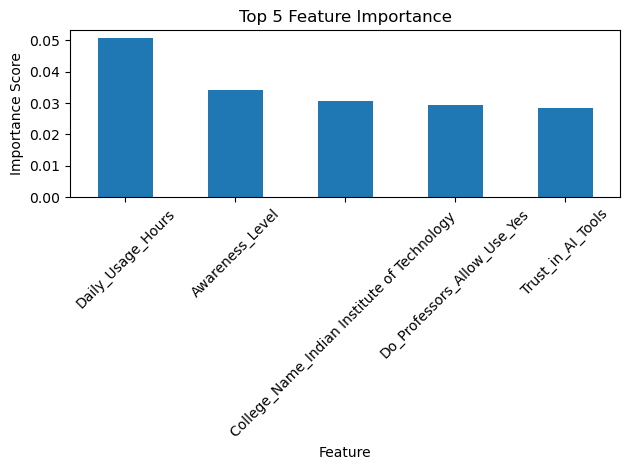

In [24]:
import matplotlib.pyplot as plt

top5.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False
)

plt.title("Top 5 Feature Importance")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
# Task 4a - Gradient Boosting

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_scaled, y_clf_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [26]:
# Predictions

gb_train_pred = gb_model.predict(X_train_scaled)
gb_test_pred = gb_model.predict(X_test_scaled)

# Accuracy

gb_train_acc = accuracy_score(y_clf_train, gb_train_pred)
gb_test_acc = accuracy_score(y_clf_test, gb_test_pred)

# ROC-AUC

gb_prob = gb_model.predict_proba(X_test_scaled)[:, 1]

gb_auc = roc_auc_score(y_clf_test, gb_prob)

print("=" * 50)
print("Gradient Boosting")
print("=" * 50)

print(f"Training Accuracy : {gb_train_acc:.4f}")
print(f"Testing Accuracy  : {gb_test_acc:.4f}")
print(f"ROC-AUC Score     : {gb_auc:.4f}")

Gradient Boosting
Training Accuracy : 0.6973
Testing Accuracy  : 0.6279
ROC-AUC Score     : 0.6706


In [27]:
# Bottom 5 least important features

bottom5 = feature_importance.sort_values(
    by="Importance",
    ascending=True
).head(5)

print(bottom5)

                                                Feature  Importance
805   College_Name_Model Institute of Engineering an...         0.0
1192     College_Name_Tantia University, Sriganganagar          0.0
573   College_Name_Indira Gandhi Government Medical ...         0.0
1191  College_Name_Tagore Government College of Educ...         0.0
575   College_Name_Indira Gandhi Institute of Medica...         0.0


In [28]:
# Remove bottom 5 features

remove_features = bottom5["Feature"].tolist()

X_train_reduced = X_train.drop(columns=remove_features)
X_test_reduced = X_test.drop(columns=remove_features)

print(X_train_reduced.shape)
print(X_test_reduced.shape)

(2891, 1676)
(723, 1676)


In [29]:
# Scale reduced dataset

scaler_reduced = StandardScaler()

X_train_reduced_scaled = scaler_reduced.fit_transform(X_train_reduced)
X_test_reduced_scaled = scaler_reduced.transform(X_test_reduced)

In [30]:
# Train reduced Random Forest

rf_reduced = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_reduced.fit(
    X_train_reduced_scaled,
    y_clf_train
)

full_auc = rf_auc

reduced_prob = rf_reduced.predict_proba(
    X_test_reduced_scaled
)[:, 1]

reduced_auc = roc_auc_score(
    y_clf_test,
    reduced_prob
)

print("=" * 50)
print("Feature Ablation")
print("=" * 50)

print(f"Full Model ROC-AUC    : {full_auc:.4f}")
print(f"Reduced Model ROC-AUC : {reduced_auc:.4f}")

Feature Ablation
Full Model ROC-AUC    : 0.7008
Reduced Model ROC-AUC : 0.6995


In [31]:
# Logistic Regression (same as Part 2)

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_clf_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [32]:
# 5-Fold Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression
lr_cv = cross_val_score(
    lr_model,
    X_train_scaled,
    y_clf_train,
    cv=cv,
    scoring="roc_auc"
)

# Controlled Decision Tree
dt_cv = cross_val_score(
    dt_control,
    X_train_scaled,
    y_clf_train,
    cv=cv,
    scoring="roc_auc"
)

# Random Forest
rf_cv = cross_val_score(
    rf_model,
    X_train_scaled,
    y_clf_train,
    cv=cv,
    scoring="roc_auc"
)

# Gradient Boosting
gb_cv = cross_val_score(
    gb_model,
    X_train_scaled,
    y_clf_train,
    cv=cv,
    scoring="roc_auc"
)

In [33]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Mean AUC": [
        lr_cv.mean(),
        dt_cv.mean(),
        rf_cv.mean(),
        gb_cv.mean()
    ],
    "Std AUC": [
        lr_cv.std(),
        dt_cv.std(),
        rf_cv.std(),
        gb_cv.std()
    ]
})

print(cv_results)

                 Model  Mean AUC   Std AUC
0  Logistic Regression  0.750728  0.016984
1        Decision Tree  0.619533  0.012004
2        Random Forest  0.703551  0.007698
3    Gradient Boosting  0.676090  0.010663


In [34]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    RandomForestClassifier(random_state=42)
)

In [35]:
param_grid = {
    "randomforestclassifier__n_estimators": [50, 100, 200],
    "randomforestclassifier__max_depth": [5, 10, None],
    "randomforestclassifier__min_samples_leaf": [1, 5]
}

In [36]:
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

grid.fit(X_train, y_clf_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestclassifier__max_depth': [5, 10, ...], 'randomforestclassifier__min_samples_leaf': [1, 5], 'randomforestclassifier__n_estimators': [50, 100, ...]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,missing_values,nan


In [37]:
print("=" * 50)
print("GridSearchCV Results")
print("=" * 50)

print("Best Parameters")
print(grid.best_params_)

print()

print("Best ROC-AUC")
print(grid.best_score_)

GridSearchCV Results
Best Parameters
{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 200}

Best ROC-AUC
0.8571323544405708


In [38]:
total_models = (
    3 *   # n_estimators
    3 *   # max_depth
    2     # min_samples_leaf
)

print("Total Model Configurations :", total_models)
print("Total Fits :", total_models * 5)

Total Model Configurations : 18
Total Fits : 90


In [39]:
best_pipeline = grid.best_estimator_

In [40]:
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]

results = []

for f in fractions:

    n = int(f * len(X_train))

    X_sub = X_train.iloc[:n]
    y_sub = y_clf_train.iloc[:n]

    best_pipeline.fit(X_sub, y_sub)

    train_prob = best_pipeline.predict_proba(X_sub)[:, 1]
    train_auc = roc_auc_score(y_sub, train_prob)

    test_prob = best_pipeline.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_clf_test, test_prob)

    results.append([f, train_auc, test_auc])

learning_curve = pd.DataFrame(
    results,
    columns=[
        "Training Fraction",
        "Training AUC",
        "Test AUC"
    ]
)

print(learning_curve)

   Training Fraction  Training AUC  Test AUC
0                0.2           1.0  0.718440
1                0.4           1.0  0.771751
2                0.6           1.0  0.809639
3                0.8           1.0  0.846968
4                1.0           1.0  0.902260


In [41]:
joblib.dump(
    best_pipeline,
    "best_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [42]:
loaded_model = joblib.load(
    "best_model.pkl"
)

sample = X_test.iloc[:2]

prediction = loaded_model.predict(sample)

print("Predictions")

print(prediction)

Predictions
[1 0]
